In [1]:
# NFL Game Exploration

In [2]:
# --- LIBRARIES ---
# "import" loads a library so we can use it. "as" gives it a short nickname.
import pandas as pd                # pandas: tools for working with tables of data
import matplotlib.pyplot as plt    # matplotlib: tools for drawing charts
import nflreadpy as nfl            # nflreadpy: downloads NFL data from the internet

# --- LOAD THE DATA ---
# range(2015, 2026) creates the numbers 2015, 2016, ..., 2025.
# Python stops BEFORE the last number, so 2026 is not included.
# This is called "end-exclusive", and it shows up everywhere in Python.
seasons = range(2015, 2026)

# load_schedules() downloads one row per game for the seasons we ask for.
# It returns a Polars DataFrame (a different table library than pandas).
# .to_pandas() converts it to a pandas DataFrame, which is what scikit-learn
# and most tutorials expect. We store the result in a variable named "games".
games = nfl.load_schedules(seasons=seasons).to_pandas()

# .head() shows the first 5 rows. The LAST line of a notebook cell is
# displayed automatically, so we don't need print().
games.head()


,game_id,season,game_type,week,gameday,weekday,gametime,away_team,away_score,home_team,...,wind,away_qb_id,home_qb_id,away_qb_name,home_qb_name,away_coach,home_coach,referee,stadium_id,stadium
0,2015_01_PIT_NE,2015,REG,1,2015-09-10,Thursday,20:30,PIT,21,NE,...,7.0,00-0022924,00-0019596,Ben Roethlisberger,Tom Brady,Mike Tomlin,Bill Belichick,Carl Cheffers,BOS00,Gillette Stadium
1,2015_01_IND_BUF,2015,REG,1,2015-09-13,Sunday,13:00,IND,14,BUF,...,15.0,00-0029668,00-0028118,Andrew Luck,Tyrod Taylor,Chuck Pagano,Rex Ryan,John Parry,BUF00,Ralph Wilson Stadium
2,2015_01_GB_CHI,2015,REG,1,2015-09-13,Sunday,13:00,GB,31,CHI,...,11.0,00-0023459,00-0024226,Aaron Rodgers,Jay Cutler,Mike McCarthy,John Fox,Craig Wrolstad,CHI98,Soldier Field
3,2015_01_KC_HOU,2015,REG,1,2015-09-13,Sunday,13:00,KC,27,HOU,...,NaN,00-0023436,00-0026625,Alex Smith,Brian Hoyer,Andy Reid,Bill O'Brien,Peter Morelli,HOU00,NRG Stadium
4,2015_01_CAR_JAX,2015,REG,1,2015-09-13,Sunday,13:00,CAR,20,JAX,...,7.0,00-0027939,00-0031407,Cam Newton,Blake Bortles,Ron Rivera,Gus Bradley,Ron Torbert,JAX00,EverBank Field


In [3]:
# .shape is an attribute (information stored on the DataFrame, so no parentheses).
# It returns (number of rows, number of columns).
# Each row is one game, so the first number is roughly the games played in 11 seasons.
games.shape

(3028, 46)

In [4]:
# .columns holds the column names. .tolist() turns them into a plain Python list
# so they print neatly. Read through them and notice anything that looks useful.
games.columns.tolist()

['game_id',
 'season',
 'game_type',
 'week',
 'gameday',
 'weekday',
 'gametime',
 'away_team',
 'away_score',
 'home_team',
 'home_score',
 'location',
 'result',
 'total',
 'overtime',
 'old_game_id',
 'gsis',
 'nfl_detail_id',
 'pfr',
 'pff',
 'espn',
 'ftn',
 'away_rest',
 'home_rest',
 'away_moneyline',
 'home_moneyline',
 'spread_line',
 'away_spread_odds',
 'home_spread_odds',
 'total_line',
 'under_odds',
 'over_odds',
 'div_game',
 'roof',
 'surface',
 'temp',
 'wind',
 'away_qb_id',
 'home_qb_id',
 'away_qb_name',
 'home_qb_name',
 'away_coach',
 'home_coach',
 'referee',
 'stadium_id',
 'stadium']

In [5]:
# .info() prints a summary of every column: its name, how many values are
# NOT empty ("non-null"), and its data type (int, float, object = text).
# If a column's non-null count is lower than the number of rows, it has
# MISSING values (shown as NaN, "not a number"). Models can't handle
# missing values directly, so spotting them now saves trouble later.
games.info()

<class 'pandas.DataFrame'>
RangeIndex: 3028 entries, 0 to 3027
Data columns (total 46 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   game_id           3028 non-null   str    
 1   season            3028 non-null   int32  
 2   game_type         3028 non-null   str    
 3   week              3028 non-null   int32  
 4   gameday           3028 non-null   str    
 5   weekday           3028 non-null   str    
 6   gametime          3028 non-null   str    
 7   away_team         3028 non-null   str    
 8   away_score        3028 non-null   int32  
 9   home_team         3028 non-null   str    
 10  home_score        3028 non-null   int32  
 11  location          3028 non-null   str    
 12  result            3028 non-null   int32  
 13  total             3028 non-null   int32  
 14  overtime          3028 non-null   int32  
 15  old_game_id       3028 non-null   str    
 16  gsis              3028 non-null   int32  
 17  nfl_de

In [6]:
# Double square brackets [[ ]] mean "give me a table with just these columns".
# The inner brackets make a Python list of column names.
# .describe() calculates count, mean, std (spread), min, max, and quartiles.
# Scan for weird values: a negative score or a rest of 50 days would signal bad data.
games[["home_score", "away_score", "home_rest", "away_rest"]].describe()

,home_score,away_score,home_rest,away_rest
count,3028.000000,3028.000000,3028.000000,3028.000000
mean,23.781704,21.883752,7.470938,7.465654
std,10.055392,9.776172,2.109995,2.049715
min,0.000000,0.000000,4.000000,4.000000
25%,17.000000,16.000000,7.000000,7.000000
50%,24.000000,21.000000,7.000000,7.000000
75%,30.000000,28.000000,7.000000,7.000000
max,70.000000,59.000000,16.000000,17.000000


In [7]:
# Step by step:
# 1. games["home_score"] > games["away_score"] compares two columns row by row.
#    The result is a column of True/False values (True = home team scored more).
# 2. .astype(int) converts True/False into 1/0, because models need numbers.
# 3. Assigning to games["home_win"] creates a NEW column with that name.
#
# Note: a tie gives False (0), so ties count as "not a home win".
# Ties are very rare, so this is fine for now.
games["home_win"] = (games["home_score"] > games["away_score"]).astype(int)

# Show the new column next to the scores so we can check it by eye.
# Does home_win = 1 exactly when home_score is bigger? Always verify!
games[["home_team", "away_team", "home_score", "away_score", "home_win"]].head(10)

,home_team,away_team,home_score,away_score,home_win
0,NE,PIT,28,21,1
1,BUF,IND,27,14,1
2,CHI,GB,23,31,0
3,HOU,KC,20,27,0
4,JAX,CAR,9,20,0
5,NYJ,CLE,31,10,1
6,STL,SEA,34,31,1
7,WAS,MIA,10,17,0
8,ARI,NO,31,19,1
9,SD,DET,33,28,1


In [8]:
# Because home_win is made of 1s and 0s, its mean (average) equals the
# FRACTION of games the home team won. For example, 0.55 means 55%.
#
# This is our BASELINE: the accuracy of the laziest strategy possible,
# "always predict the home team wins". Any model we build must beat this
# number to be worth anything.
baseline = games["home_win"].mean()

# An f-string (the f before the quotes) lets us put variables inside {}.
# :.3f means "show 3 decimal places".
print(f"Home team wins {baseline:.3f} of games")

Home team wins 0.548 of games


In [9]:
# groupby() splits the table into groups (one group per season).
# ["home_win"] selects the column we care about inside each group.
# .mean() averages it within each group.
# Result: one number per season = that season's home win rate.
by_season = games.groupby("season")["home_win"].mean()

# Display the result as a table so you can read the exact numbers.
by_season

season
2015    0.543071
2016    0.580524
2017    0.569288
2018    0.591760
2019    0.520599
2020    0.498141
2021    0.515789
2022    0.563380
2023    0.564912
2024    0.547368
2025    0.533333
Name: home_win, dtype: float64

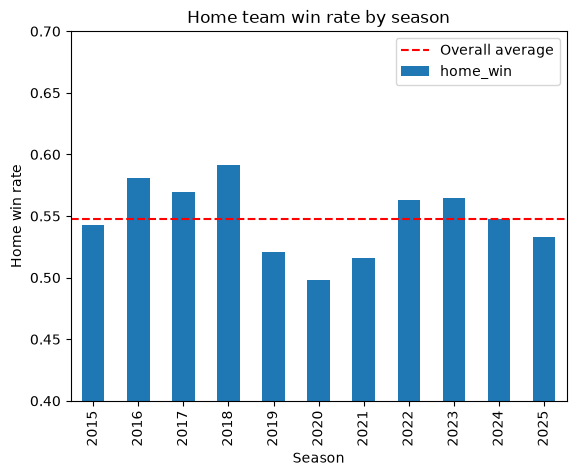

In [10]:
# .plot(kind="bar") draws a bar chart from the grouped data.
# pandas uses matplotlib behind the scenes, which is why we imported plt.
by_season.plot(kind="bar")

plt.title("Home team win rate by season")  # Chart title
plt.xlabel("Season")                        # Label for the x-axis
plt.ylabel("Home win rate")                 # Label for the y-axis

# ylim sets the y-axis range. Without it, the chart starts at 0 and all the
# bars look nearly identical. Zooming in to 0.4-0.7 makes differences visible.
# (Careful: zoomed charts can exaggerate small differences, so read the numbers too.)
plt.ylim(0.4, 0.7)

# A dashed horizontal line at the overall baseline for comparison.
plt.axhline(baseline, color="red", linestyle="--", label="Overall average")
plt.legend()  # Shows the label for the red line

plt.show()    # Draws the chart

In [11]:
# Create a new column: home team's rest days minus away team's rest days.
# Positive = the home team had MORE rest. Negative = the away team did.
games["rest_diff"] = games["home_rest"] - games["away_rest"]

# Group games into three categories using a simple function:
def rest_category(diff):
    # A function is a reusable block of code. "def" defines it, and "diff" is
    # the input it receives. "return" sends the answer back.
    if diff > 0:
        return "Home more rest"
    elif diff < 0:
        return "Away more rest"
    else:
        return "Equal rest"

# .apply() runs our function on every value in the column.
games["rest_group"] = games["rest_diff"].apply(rest_category)

# Home win rate for each group. .agg() lets us calculate several things at once:
# the mean win rate AND how many games are in each group (so we can tell if a
# group is too small to trust).
games.groupby("rest_group")["home_win"].agg(["mean", "count"])

,mean,count
rest_group,,
Away more rest,0.545614,570
Equal rest,0.540610,1933
Home more rest,0.577143,525


In [12]:
   # isna() marks missing values as True; sum() counts them
   games[["home_rest", "away_rest"]].isna().sum()

home_rest    0
away_rest    0
dtype: int64

In [13]:
   games["home_win"].mean()

np.float64(0.547886393659181)